<a href="https://colab.research.google.com/github/Rylan-Thompson-hub/OCR_Project/blob/main/OCR_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Optical Character Recognition (OCR)

**Deliverable:** Notebook which evaluates a character recognizer on the `harieh/ocr-dataset`.

**Contents:**
- Setup & dataset loading
- Baseline: Logistic Regression
- RNN model: LSTM-based classifier
- Evaluation (accuracy, confusion matrix, sample predictions)

**Notes:** The notebook assumes the dataset is available on disk at `/content/ocr_data`. If you used the kagglehub download, the dataset. Adjust `DATA_PATH` below if needed. *This Project has not been tested outside of Google Colab.*

---

## Environment & Dependencies
On Colab you may need to run `!pip install tensorflow scikit-learn matplotlib seaborn opencv-python-headless` if any are missing. The training uses TensorFlow/Keras for the LSTM model and scikit-learn for baselines and utilities.

If you are using colab, ensure you are on T4 GPU



## Project Focus Elaboration

The purpose of this project is to explore how Optical Character Recognition (OCR) has evolved with the integration of Artificial Intelligence, particularly machine learning and deep learning methods. Traditional OCR systems relied heavily on rule-based pattern matching and often struggled with noisy images such as: handwriting, variations in font, and real-world inconsistencies.

With the introduction of AI—especially convolutional neural networks (CNNs), recurrent neural networks (RNNs), and transformer-based architectures—OCR accuracy has improved dramatically. Modern systems can not only recognize clean printed characters but also handle handwritten text, skewed images, variable lighting, and diverse writing styles. AI-powered OCR has also expanded the capabilities of character recognition to include **multi-language support**, real-time detection, document understanding, and automatic error correction.

This project examines some of those advancements by evaluating multiple OCR models, including both traditional methods (Logistic Regression) and modern deep learning approaches (LSTM and CNN classifiers). By comparing their performance throughout this notebook file.

In [ ]:
# Optional
# !pip install tensorflow scikit-learn matplotlib seaborn opencv-python-headless

In [ ]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import itertools
import pickle

# Config
DATA_PATH = "/content/ocr_data"

IMG_SIZE = (28, 28)
RANDOM_STATE = 64
TEST_SIZE = 0.10
VALIDATION_SPLIT = 0.10

print("DATA_PATH:", DATA_PATH)

DATA_PATH: /content/ocr_data


In [ ]:
import kagglehub, os, shutil

# Download dataset via kagglehub
cache_path = kagglehub.dataset_download("harieh/ocr-dataset")

# Warning: There is a lot of data, if your system cant handle this, use Google Colab and be patient while it downloads direct to the env.
os.makedirs(DATA_PATH, exist_ok=True)
source_folder = os.path.join(cache_path, "dataset")
shutil.copytree(source_folder, DATA_PATH, dirs_exist_ok=True)

print("Dataset extracted to:", DATA_PATH)

100%|██████████| 153M/153M [00:08<00:00, 19.7MB/s]

Extracting files...


Dataset extracted to: /content/ocr_data


## Load dataset

This cell reads images, normalizes them, and creates label mappings, for this project we will load into memory (210k images).

In [ ]:
# Load images and labels
import glob
from tqdm import tqdm

classes = sorted([d for d in os.listdir(DATA_PATH) if os.path.isdir(os.path.join(DATA_PATH, d))])
print("Found classes:", len(classes))
label_map = {cls: idx for idx, cls in enumerate(classes)}
inv_label_map = {v: k for k, v in label_map.items()}

X = []
y = []
max_samples_per_class = None

for cls in classes:
    folder = os.path.join(DATA_PATH, cls)
    files = glob.glob(os.path.join(folder, "*"))
    if max_samples_per_class:
        files = files[:max_samples_per_class]
    for f in files:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        img = cv2.resize(img, IMG_SIZE)
        X.append(img)
        y.append(label_map[cls])

X = np.array(X, dtype=np.float32) / 255.0  # normalize to [0,1]
y = np.array(y, dtype=np.int32)

print("Total images loaded:", len(X))
print("Shape of X:", X.shape)

Found classes: 62
Total images loaded: 210227
Shape of X: (210227, 28, 28)


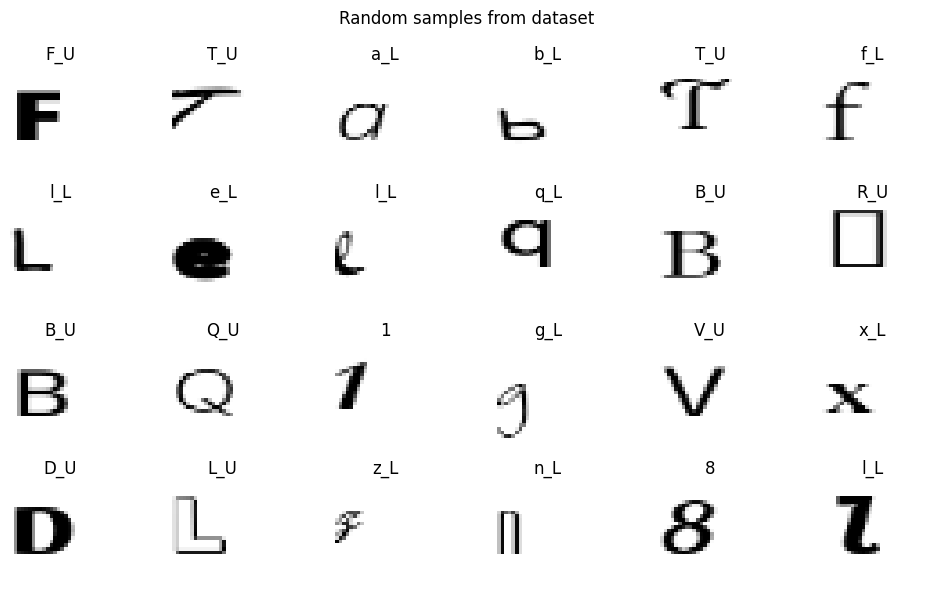

In [ ]:
# show a grid of random samples
import random
plt.figure(figsize=(10,6))
samples = random.sample(range(len(X)), min(24, len(X)))
for i, idx in enumerate(samples):
    plt.subplot(4,6,i+1)
    plt.imshow(X[idx], cmap='gray')
    plt.title(inv_label_map[y[idx]])
    plt.axis('off')
plt.suptitle("Random samples from dataset")
plt.tight_layout()

\## Load the Premade Model (h5/pkl required)

This is an alternative section, if you already have the model files saved.

THIS WILL ALWAYS THROW AN ERROR IF YOU DONT HAVE THE MODELS PRETRAINED

In [ ]:
import os
import pickle
import numpy as np
from tensorflow.keras.models import load_model
from PIL import Image

MODEL_PATH = "/content/lstm_model.h5"
LABELMAP_PATH = "/content/label_map.pkl"

# Only run this section if you have the Model Pre-Trained
if not os.path.exists(MODEL_PATH):
    print("Model file not found")
    raise SystemExit

if not os.path.exists(LABELMAP_PATH):
    print("Label map file not found")
    raise SystemExit

print("Loading LSTM model...")
model = load_model(MODEL_PATH)

print("Loading label map...")
with open(LABELMAP_PATH, "rb") as f:
    # The file label_map.pkl contains the mapping from integer index to character string
    # (as it was saved as `inv_label_map` in cell _ESasHG6Q--s).
    # This is exactly what `inv_label_map` should be for converting predicted class index back to label.
    inv_label_map = pickle.load(f)

# Re-create `label_map` (character string to integer index) for consistency if it's used elsewhere in the notebook.
# However, for prediction in this cell, only `inv_label_map` is strictly necessary.
label_map = {v: k for k, v in inv_label_map.items()}

def load_and_prepare_image(path):
    """
    reshapes Image to (1, 28, 28) for LSTM
    """
    img = Image.open(path).convert("L")
    img = img.resize((28, 28))
    arr = np.array(img, dtype=np.float32) / 255.0
    return arr.reshape(1, 28, 28)


# CHANGE THIS PATH to the Classification image
TEST_IMAGE = "/content/image2classify2.jpg"

if not os.path.exists(TEST_IMAGE):
    print(f"{TEST_IMAGE} not found")
    raise SystemExit

print(f"Working...")

X = load_and_prepare_image(TEST_IMAGE)

probs = model.predict(X)
pred_class = probs.argmax()
pred_label = inv_label_map[pred_class]

print("Predicted label:", pred_label)
print("Class probabilities:", probs[0])


Model file not found


SystemExit: 

/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## Train/Test split

We split into train and test sets; later we'll split train further for validation during model.fit (Keras supports validation_split).


In [ ]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))


Train size: 189204
Test size: 21023



## Logistic Regression

We'll train a logistic regression classifier as a simple baseline


In [ ]:
# Flatten images
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print("Flat shape:", X_train_flat.shape)

# Train logistic regression baseline
clf = LogisticRegression(max_iter=400, n_jobs=-1, verbose=1)
clf.fit(X_train_flat, y_train)

# Evaluate
y_pred = clf.predict(X_test_flat)
acc = accuracy_score(y_test, y_pred)
print(f"Logistic Regression test accuracy: {acc:.4f}")


Flat shape: (189204, 784)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


Logistic Regression test accuracy: 0.6784


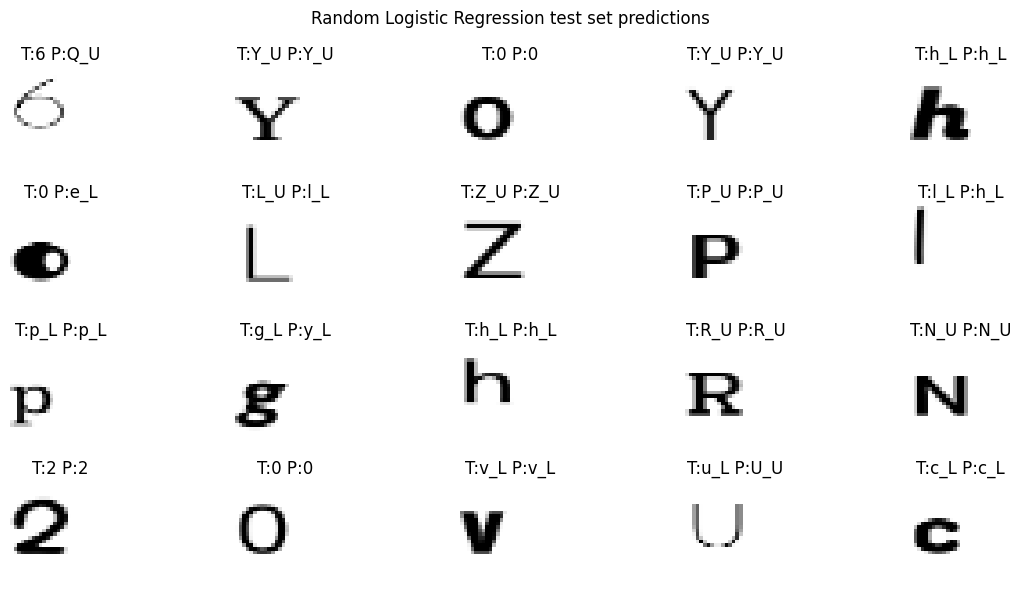

In [ ]:
import random
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
samples = random.sample(range(len(X_test_flat)), min(20, len(X_test_flat)))

for i, idx in enumerate(samples):
    plt.subplot(4,5,i+1)

    img = X_test_flat[idx].reshape(28,28)
    plt.imshow(img, cmap='gray')

    true_label = inv_label_map[y_test[idx]]
    pred_label = inv_label_map[clf.predict(X_test_flat[idx].reshape(1,-1))[0]]

    plt.title(f"T:{true_label} P:{pred_label}")
    plt.axis('off')

plt.suptitle("Random Logistic Regression test set predictions")
plt.tight_layout()
plt.show()

## LSTM classifier (Keras)

We interpret each image as a sequence of 28 rows; each row has 28 features. The LSTM will process the rows sequentially and produce a class prediction.

This section builds the model, trains it, and evaluates performance


In [ ]:
# Prepare sequence data (28 timesteps x 28 features)
X_train_seq = X_train.reshape(-1, IMG_SIZE[0], IMG_SIZE[1])
X_test_seq = X_test.reshape(-1, IMG_SIZE[0], IMG_SIZE[1])

print("Sequence shape:", X_train_seq.shape)

In [ ]:
# Build LSTM model
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

def build_lstm_model(input_shape=(28,28), lstm_units=128, dense_units=128, dropout=0.2, num_classes=len(classes)):
    inputs = layers.Input(shape=input_shape, name='input_image')
    # LSTM expects shape (timesteps, features)
    x = layers.LSTM(lstm_units, name='lstm')(inputs)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model = models.Model(inputs=inputs, outputs=outputs)
    return model

model = build_lstm_model(input_shape=(IMG_SIZE[0], IMG_SIZE[1]), lstm_units=128, dense_units=128, dropout=0.2)
model.compile(optimizer=optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 62)             │         7,998 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,894 (409.74 KB)

 Trainable params: 104,894 (409.74 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train (this may take time depending on data size)
history = model.fit(
    X_train_seq, y_train,
    validation_split=VALIDATION_SPLIT,
    epochs=15,
    batch_size=128,
    callbacks=[es, mc]
)


In [ ]:
# Save model & Label Map
model_path = os.path.join('/content/lstm_model.h5')
model.save(model_path)

# Save label map
with open(os.path.join('/content/label_map.pkl'), 'wb') as f:
    pickle.dump(inv_label_map, f)

print("Saved the LSTM Model and Labels to /content/")


In [ ]:
# Plot training history
def plot_history(h):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(h.history['loss'], label='train_loss')
    plt.plot(h.history['val_loss'], label='val_loss')
    plt.legend()
    plt.title('Loss')
    plt.subplot(1,2,2)
    plt.plot(h.history['accuracy'], label='train_acc')
    plt.plot(h.history['val_accuracy'], label='val_acc')
    plt.legend()
    plt.title('Accuracy')
    plt.show()

plot_history(history)

## Evaluation

In [ ]:
# Evaluate on test set
test_loss, test_acc = model.evaluate(X_test_seq, y_test, verbose=1)
print("LSTM Test accuracy:", test_acc)

In [ ]:
# Predictions and confusion matrix
y_pred_probs = model.predict(X_test_seq)
y_pred = y_pred_probs.argmax(axis=1)

acc = accuracy_score(y_test, y_pred)
print("Computed accuracy:", acc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,10))
sns.heatmap(cm, cmap='Blues', xticklabels=classes, yticklabels=classes, vmax=50)
plt.title("Confusion matrix (counts) — may be large for 62 classes")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [ ]:
# display random predictions
import random
plt.figure(figsize=(12,6))
samples = random.sample(range(len(X_test_seq)), min(20, len(X_test_seq)))
for i, idx in enumerate(samples):
    plt.subplot(4,5,i+1)
    plt.imshow(X_test_seq[idx], cmap='gray')
    true_label = inv_label_map[y_test[idx]]
    pred_label = inv_label_map[y_pred[idx]]
    plt.title(f"T:{true_label} P:{pred_label}")
    plt.axis('off')
plt.suptitle("Random test set predictions")
plt.tight_layout()



## Further Developement

Images of characters are extremely regular — models tend to overfit quickly. Dropout is something I could use as it is one of the easiest tools to prevent overfitting.

Potentially using CNN models:
CNN(standard), Karas (Conv2D → MaxPool → Conv2D → Dense)

In [ ]:
# --- Small CNN Model for OCR ---

import tensorflow as tf
from tensorflow.keras import layers, models

def build_small_cnn(input_shape=(28, 28, 1), num_classes=len(classes)):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Prepare CNN input shape (add channel dimension)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn  = X_test.reshape(-1, 28, 28, 1)

cnn = build_small_cnn()
cnn.summary()

# Train
history_cnn = cnn.fit(
    X_train_cnn, y_train,
    epochs=10,
    validation_split=0.1,
    batch_size=128
)

# Evaluate
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test)
print("CNN test accuracy:", test_acc)
